# Replicação de *Failing Loudly* (Rabanser, Günnemann & Lipton, NeurIPS 2019) em MNIST e CIFAR-10

Pergunta do artigo: dado um modelo treinado em dados de origem, qual combinação de **redução de dimensionalidade (DR)** e **teste de duas amostras** detecta melhor que os dados de produção mudaram, e com quantas amostras?

Desenho replicado (seção 4 do artigo):

- **Dados:** MNIST (50.000 de treino, 10.000 de validação, 10.000 de teste) e CIFAR-10 (40.000 / 10.000 / 10.000). O treino é fixo; a separação validação (origem) / teste (alvo) muda a cada uma das 5 rodadas.
- **DR:** NoRed, PCA, SRP, UAE e TAE com K = 32; BBSDs (softmax do classificador, 10 dimensões); BBSDh (classe prevista); Classif (classificador de domínio).
- **Testes:** KS por dimensão + Bonferroni (univariado); MMD com permutação (multivariado, só até 1.000 amostras, como no artigo); qui-quadrado para BBSDh; binomial para Classif. α = 0,05.
- **Shifts no conjunto de teste:** ruído gaussiano (σ ∈ {1, 10, 100}), imagem (rotação/translação/zoom pequeno, médio, grande), adversarial (FGSM), knock-out da classe 0, imagem média + knock-out e só-classe-0 + imagem média, cada um com fração afetada δ ∈ {0,1; 0,5; 1,0}, além do caso sem shift.
- **Métrica:** acurácia de detecção = fração de (dataset, shift, δ, rodada) em que o teste rejeita H0, por tamanho de amostra s ∈ {10, …, 10.000}. A tabela 1 do artigo agrega MNIST e CIFAR-10 da mesma forma.

Diferenças em relação ao artigo (por custo ou por falta de detalhe no texto):

| Item | Artigo | Aqui |
|---|---|---|
| Classificador de rótulo e de domínio | ResNet-18, SGD, até 200 épocas com early stopping | CNN pequena (2 blocos em MNIST, 3 em CIFAR-10), Adam, poucas épocas |
| Autoencoder | 3 conv + 1 densa | Igual em estrutura; TAE treinado por poucas épocas |
| Kernel do MMD | gaussiano, σ = "distância mediana" | gaussiano exp(−d²/σ) com σ = mediana das distâncias ao quadrado; 1.000 permutações |
| FGSM | ε não informado no texto | ε = 0,1 sobre o próprio classificador BBSD, nos dois datasets |
| Transformação de imagem | Keras `ImageDataGenerator` | `torchvision` `RandomAffine` com os mesmos limites |
| Amostra de origem | não explícito | s amostras da validação contra s amostras do teste |
| MNIST→USPS, COIL-100, splits originais | incluídos | não incluídos |

In [2]:
import os, time, math, warnings, contextlib, io
from pathlib import Path

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import torchvision.transforms.v2 as T
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.random_projection import SparseRandomProjection

QUICK = os.environ.get("FL_QUICK") == "1"   # execução reduzida, só para testar o notebook
DEV = "cuda" if torch.cuda.is_available() else "cpu"
DATA, OUT = Path("data"), Path("resultados")
OUT.mkdir(exist_ok=True)
SEED, ALPHA, K = 0, 0.05, 32
RUNS = 1 if QUICK else 5
SIZES = [10, 20, 50, 100, 200, 500, 1000, 10000]
MMD_MAX, N_PERM = 1000, 1000
DATASETS = ["mnist", "cifar10"]
# épocas: classificador de rótulo, autoencoder treinado, classificador de domínio
SPEC = {"mnist": dict(n_tr=50000, ep_clf=5, ep_ae=5, ep_dom=10),
        "cifar10": dict(n_tr=40000, ep_clf=15, ep_ae=10, ep_dom=5)}
if QUICK:
    SPEC = {k: {**v, "ep_clf": 1, "ep_ae": 1, "ep_dom": 2} for k, v in SPEC.items()}
warnings.filterwarnings("ignore", message="ks_2samp: Exact calculation unsuccessful")
print(DEV, torch.__version__, "QUICK" if QUICK else "completo")

cuda 2.14.1+cu130 completo


## 1. Dados

In [3]:
def load(name):
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):   # sem barra de download
        if name == "mnist":
            tr = torchvision.datasets.MNIST(DATA, train=True, download=True)
            te = torchvision.datasets.MNIST(DATA, train=False, download=True)
            X = torch.cat([tr.data, te.data]).float().div(255).unsqueeze(1)
            y = torch.cat([tr.targets, te.targets])
        else:
            tr = torchvision.datasets.CIFAR10(DATA, train=True, download=True)
            te = torchvision.datasets.CIFAR10(DATA, train=False, download=True)
            X = torch.as_tensor(np.concatenate([tr.data, te.data])).permute(0, 3, 1, 2).float().div(255)
            y = torch.as_tensor(tr.targets + te.targets)
    perm = np.random.default_rng(SEED).permutation(len(X))
    n_tr = SPEC[name]["n_tr"]
    idx_tr, idx_rest = perm[:n_tr], perm[n_tr:n_tr + 20000]   # treino fixo; validação/teste sorteados por rodada
    return X.to(DEV), y.to(DEV), idx_tr, idx_rest


for name in DATASETS:
    X, y, idx_tr, idx_rest = load(name)
    print(name, tuple(X.shape), "treino", len(idx_tr), "validação + teste", len(idx_rest))

mnist (70000, 1, 28, 28) treino 50000 validação + teste 20000
cifar10 (60000, 3, 32, 32) treino 40000 validação + teste 20000


## 2. Modelos e reduções de dimensionalidade (treinados só com o conjunto de treino)

In [4]:
class CNN(nn.Module):
    # Classificador usado no BBSD (10 saídas) e no classificador de domínio (2 saídas).
    # MNIST: 2 blocos convolucionais (28 → 7); CIFAR-10: 3 blocos (32 → 4).
    def __init__(self, c, hw, n_out=10):
        super().__init__()
        chans = [c, 32, 64] if hw == 28 else [c, 32, 64, 128]
        layers = []
        for a, b in zip(chans, chans[1:]):
            layers += [nn.Conv2d(a, b, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        side = hw // 2 ** (len(chans) - 1)
        self.f = nn.Sequential(*layers, nn.Flatten(), nn.Linear(chans[-1] * side * side, 128), nn.ReLU(),
                               nn.Linear(128, n_out))

    def forward(self, x):
        return self.f(x)


class AE(nn.Module):
    # 3 camadas convolucionais + 1 densa até o latente K = 32, como no artigo
    def __init__(self, c, hw):
        super().__init__()
        q = hw // 4
        self.enc = nn.Sequential(
            nn.Conv2d(c, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.Flatten(), nn.Linear(64 * q * q, K))
        self.dec = nn.Sequential(
            nn.Linear(K, 64 * q * q), nn.ReLU(), nn.Unflatten(1, (64, q, q)),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, c, 4, stride=2, padding=1), nn.Sigmoid())

    def forward(self, x):
        return self.dec(self.enc(x))


def fit(model, X, target, loss_fn, epochs, bs=128, lr=1e-3):
    model.to(DEV).train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        for i in torch.randperm(len(X), device=DEV).split(bs):
            opt.zero_grad()
            loss_fn(model(X[i]), target[i]).backward()
            opt.step()
    return model.eval()


@torch.no_grad()
def apply(fn, X, bs=2000):
    return torch.cat([fn(X[i:i + bs]) for i in range(0, len(X), bs)])


np_ = lambda t: t.cpu().numpy()


def build_dr(name, X, y, idx_tr, idx_rest):
    sp, (c, hw) = SPEC[name], (X.shape[1], X.shape[2])
    X_tr, y_tr = X[idx_tr], y[idx_tr]
    t0 = time.time()
    torch.manual_seed(SEED)
    clf = fit(CNN(c, hw), X_tr, y_tr, F.cross_entropy, sp["ep_clf"])
    tae = fit(AE(c, hw), X_tr, X_tr, F.mse_loss, sp["ep_ae"])
    torch.manual_seed(SEED)
    uae = AE(c, hw).to(DEV).eval()                # pesos aleatórios, nunca treinado
    flat_tr = np_(X_tr.flatten(1))
    pca = PCA(K, random_state=SEED).fit(flat_tr)
    srp = SparseRandomProjection(K, random_state=SEED).fit(flat_tr)
    acc = (apply(clf, X[idx_rest]).argmax(1) == y[idx_rest]).float().mean().item()
    print(f"{name}: acurácia do classificador fora do treino {acc:.4f}; "
          f"variância explicada pelo PCA {pca.explained_variance_ratio_.sum():.2f}; {time.time() - t0:.0f}s")
    DR = {
        "NoRed": lambda X: np_(X.flatten(1)),
        "PCA": lambda X: pca.transform(np_(X.flatten(1))),
        "SRP": lambda X: srp.transform(np_(X.flatten(1))),
        "UAE": lambda X: np_(apply(uae.enc, X)),
        "TAE": lambda X: np_(apply(tae.enc, X)),
        "BBSDs": lambda X: np_(apply(lambda x: clf(x).softmax(1), X)),
    }
    return DR, clf

## 3. Testes de duas amostras

- **KS + Bonferroni:** KS em cada dimensão; p-valor agregado = min(1, K · min p).
- **MMD:** estimador não viesado (eq. 3 do artigo), kernel gaussiano, p-valor por permutação (k + 1)/(B + 1), calculado na GPU com todas as permutações de uma vez.
- **Qui-quadrado:** homogeneidade 2 × C entre as classes previstas (BBSDh).
- **Binomial:** o classificador de domínio treina com metade de cada amostra e é avaliado na outra metade; testa se a acurácia supera 0,5.

In [5]:
def ks_bonf(a, b):
    p = stats.ks_2samp(a, b, axis=0).pvalue
    p = np.nan_to_num(p, nan=1.0)                 # dimensões constantes nas duas amostras
    return min(1.0, p.min() * a.shape[1])


def mmd_perm(a, b, n_perm=N_PERM):
    Z = torch.as_tensor(np.vstack([a, b]), dtype=torch.float32, device=DEV)
    m, N = len(a), len(Z)
    n = N - m
    D2 = torch.cdist(Z, Z).pow(2)
    off = ~torch.eye(N, dtype=torch.bool, device=DEV)
    sigma = D2[off].median().clamp_min(1e-12)
    Kd = torch.exp(-D2 / sigma) * off             # diagonal zerada: termos i ≠ j

    def stat(A):                                  # A: (P, N) indicadores da amostra 1
        B = 1 - A
        AK = A @ Kd
        return ((AK * A).sum(1) / (m * (m - 1)) + ((B @ Kd) * B).sum(1) / (n * (n - 1))
                - 2 * (AK * B).sum(1) / (m * n))

    a0 = torch.zeros(1, N, device=DEV); a0[0, :m] = 1
    obs = stat(a0)
    A = (torch.argsort(torch.rand(n_perm, N, device=DEV), 1) < m).float()   # m posições sorteadas
    return ((stat(A) >= obs).sum().item() + 1) / (n_perm + 1)


def chi2_hard(a, b, C=10):
    t = np.array([np.bincount(a, minlength=C), np.bincount(b, minlength=C)])
    t = t[:, t.sum(0) > 0]
    return 1.0 if t.shape[1] < 2 else stats.chi2_contingency(t)[1]


def domain_classif(Xs, Xt, epochs):
    hs, ht = len(Xs) // 2, len(Xt) // 2
    Xa = torch.cat([Xs[:hs], Xt[:ht]])
    ya = torch.cat([torch.zeros(hs), torch.ones(ht)]).long().to(DEV)
    bs = 32 if len(Xa) < 2000 else 128
    model = fit(CNN(Xs.shape[1], Xs.shape[2], 2), Xa, ya, F.cross_entropy, epochs=epochs, bs=bs)
    Xb = torch.cat([Xs[hs:], Xt[ht:]])
    yb = torch.cat([torch.zeros(len(Xs) - hs), torch.ones(len(Xt) - ht)]).long().to(DEV)
    k = (apply(model, Xb).argmax(1) == yb).sum().item()
    return stats.binomtest(k, len(yb), 0.5, alternative="greater").pvalue


# autoverificação rápida: sob H0 os p-valores não devem ser minúsculos; sob shift forte, sim
r = np.random.default_rng(0)
x0, x1 = r.normal(size=(200, 5)), r.normal(size=(200, 5))
assert ks_bonf(x0, x1) > 0.01 and mmd_perm(x0, x1) > 0.01
assert ks_bonf(x0, x1 + 1) < 1e-6 and mmd_perm(x0, x1 + 1) < 0.01
assert chi2_hard(np.repeat(np.arange(10), 20), np.zeros(200, int)) < 1e-6

## 4. Shifts aplicados ao conjunto de teste

A fração δ de amostras afetadas é sorteada a cada rodada. Os níveis de imagem seguem o artigo: pequeno (10°, 5%, 10%), médio (40°, 20%, 20%) e grande (90°, 40%, 40%) para rotação, translação e zoom. A "classe 0" é o dígito 0 no MNIST e "avião" no CIFAR-10.

In [6]:
IMG = {"s": (10, 0.05, 0.1), "m": (40, 0.2, 0.2), "l": (90, 0.4, 0.4)}
GN = {"s": 1, "m": 10, "l": 100}                  # desvio padrão na escala 0–255


def pick(n, frac, g):
    return torch.randperm(n, generator=g)[: int(round(frac * n))].to(DEV)


def img_shift(X, idx, lvl):
    deg, tr_, zm = IMG[lvl]
    aug = T.RandomAffine(degrees=deg, translate=(tr_, tr_), scale=(1 - zm, 1 + zm))
    X[idx] = torch.stack([aug(x) for x in X[idx]]) if len(idx) else X[idx]


def fgsm(clf, X, y, idx, eps=0.1):
    for c in idx.split(2000):
        x = X[c].clone().requires_grad_(True)
        grad, = torch.autograd.grad(F.cross_entropy(clf(x), y[c]), x)
        X[c] = (x + eps * grad.sign()).clamp(0, 1).detach()


def knockout(X, y, frac, g):
    zeros = torch.nonzero(y == 0).squeeze(1)
    drop = zeros[pick(len(zeros), frac, g)]
    keep = torch.ones(len(y), dtype=torch.bool, device=DEV); keep[drop] = False
    return X[keep], y[keep]


def make_target(kind, delta, X, y, g, clf):
    X, y = X.clone(), y.clone()
    if kind.endswith("_gn"):
        i = pick(len(X), delta, g)
        X[i] = (X[i] + torch.randn(X[i].shape, generator=g).to(DEV) * GN[kind[0]] / 255).clamp(0, 1)
    elif kind.endswith("_img") and len(kind) == 5:
        img_shift(X, pick(len(X), delta, g), kind[0])
    elif kind == "adv":
        fgsm(clf, X, y, pick(len(X), delta, g))
    elif kind == "ko":
        X, y = knockout(X, y, delta, g)
    elif kind == "m_img+ko":
        X, y = knockout(X, y, delta, g)
        img_shift(X, pick(len(X), 0.5, g), "m")
    elif kind == "oz+m_img":
        X, y = X[y == 0], y[y == 0]
        img_shift(X, pick(len(X), delta, g), "m")
    return X, y


KINDS = ["s_gn", "m_gn", "l_gn", "s_img", "m_img", "l_img", "adv", "ko", "m_img+ko", "oz+m_img"]
SHIFTS = [("no_shift", 0.0)] + [(k, d) for k in KINDS for d in (0.1, 0.5, 1.0)]
if QUICK:
    SHIFTS = [("no_shift", 0.0), ("l_gn", 1.0), ("m_img", 0.5), ("ko", 1.0), ("adv", 0.5)]
print(len(SHIFTS), "configurações de shift por dataset")

31 configurações de shift por dataset


## 5. Experimento

Para cada dataset, rodada e shift: as representações da validação (origem) e do teste deslocado (alvo) são calculadas uma vez, e cada tamanho s usa as primeiras s amostras de uma ordem aleatória. Os resultados ficam em `resultados/resultados_<dataset>.csv`; se o arquivo já existir, o notebook só o carrega. Apague o arquivo para rodar de novo (numa RTX 3060: cerca de 15 min para MNIST e de 1 a 1,5 h para CIFAR-10). Cada rodada também é salva em `resultados/parcial_*.csv`; se a execução for interrompida, ela retoma da rodada seguinte.

In [7]:
def run_experiment(name, X_all, y_all, idx_rest, DR, clf, tag):
    for run in range(RUNS):
        ckpt = OUT / f"parcial_{tag}_rodada{run}.csv"          # checkpoint: retoma da rodada que parou
        if ckpt.exists():
            continue
        rows = []
        p = np.random.default_rng(100 + run).permutation(idx_rest)
        Xv, yv = X_all[p[:10000]], y_all[p[:10000]]
        Xt0, yt0 = X_all[p[10000:]], y_all[p[10000:]]
        rep_v = {k: f(Xv) for k, f in DR.items()}
        for j, (kind, delta) in enumerate(SHIFTS):
            t0 = time.time()
            g = torch.Generator().manual_seed(1000 * run + j)
            torch.manual_seed(1000 * run)                       # aleatoriedade do RandomAffine
            Xt, yt = make_target(kind, delta, Xt0, yt0, g, clf)
            rep_t = {k: f(Xt) for k, f in DR.items()}
            ov = np.random.default_rng(run).permutation(len(Xv))
            ot = np.random.default_rng(run + 1).permutation(len(Xt))
            for s in SIZES:
                n = min(s, len(Xt))                             # oz+m_img tem só ~1.000 imagens da classe 0
                sv, st = ov[:n], ot[:n]
                base = dict(dataset=name, run=run, shift=kind, delta=delta, s=s, n=n)
                for k in DR:
                    rows.append({**base, "teste": "Univ", "dr": k, "p": ks_bonf(rep_v[k][sv], rep_t[k][st])})
                    if s <= MMD_MAX:
                        rows.append({**base, "teste": "Multiv", "dr": k, "p": mmd_perm(rep_v[k][sv], rep_t[k][st])})
                hv, ht = rep_v["BBSDs"][sv].argmax(1), rep_t["BBSDs"][st].argmax(1)
                rows.append({**base, "teste": "χ²", "dr": "BBSDh", "p": chi2_hard(hv, ht)})
                rows.append({**base, "teste": "Bin", "dr": "Classif",
                             "p": domain_classif(Xv[torch.as_tensor(sv, device=DEV)],
                                                 Xt[torch.as_tensor(st, device=DEV)], SPEC[name]["ep_dom"])})
            print(f"{name} rodada {run} {kind:9s} δ={delta:.1f}: {time.time() - t0:5.1f}s", flush=True)
        pd.DataFrame(rows).to_csv(ckpt, index=False)
    return pd.concat([pd.read_csv(OUT / f"parcial_{tag}_rodada{run}.csv") for run in range(RUNS)])


parts = []
for name in DATASETS:
    tag = f"{name}_quick" if QUICK else name
    path = OUT / f"resultados_{tag}.csv"
    X_all, y_all, idx_tr, idx_rest = load(name)
    DR, clf = build_dr(name, X_all, y_all, idx_tr, idx_rest)
    if not path.exists():
        t0 = time.time()
        run_experiment(name, X_all, y_all, idx_rest, DR, clf, tag).to_csv(path, index=False)
        print(f"{name}: {(time.time() - t0) / 60:.1f} min")
    parts.append(pd.read_csv(path))
    del X_all; torch.cuda.empty_cache()
res = pd.concat(parts, ignore_index=True)
res["detect"] = res["p"] < ALPHA
res.groupby("dataset").size()

mnist: acurácia do classificador fora do treino 0.9866; variância explicada pelo PCA 0.74; 9s
cifar10: acurácia do classificador fora do treino 0.7215; variância explicada pelo PCA 0.80; 25s
cifar10 rodada 0 no_shift  δ=0.0:  15.3s
cifar10 rodada 0 s_gn      δ=0.1:  14.0s
cifar10 rodada 0 s_gn      δ=0.5:  14.3s
cifar10 rodada 0 s_gn      δ=1.0:  14.4s
cifar10 rodada 0 m_gn      δ=0.1:  13.8s
cifar10 rodada 0 m_gn      δ=0.5:  14.2s
cifar10 rodada 0 m_gn      δ=1.0:  14.3s
cifar10 rodada 0 l_gn      δ=0.1:  13.8s
cifar10 rodada 0 l_gn      δ=0.5:  14.9s
cifar10 rodada 0 l_gn      δ=1.0:  15.3s
cifar10 rodada 0 s_img     δ=0.1:  15.5s
cifar10 rodada 0 s_img     δ=0.5:  17.2s
cifar10 rodada 0 s_img     δ=1.0:  19.5s
cifar10 rodada 0 m_img     δ=0.1:  14.8s
cifar10 rodada 0 m_img     δ=0.5:  16.2s
cifar10 rodada 0 m_img     δ=1.0:  18.0s
cifar10 rodada 0 l_img     δ=0.1:  14.3s
cifar10 rodada 0 l_img     δ=0.5:  16.1s
cifar10 rodada 0 l_img     δ=1.0:  18.4s
cifar10 rodada 0 adv       δ=0

dataset
cifar10    16430
mnist      16430
dtype: int64

## 6. Resultados

### 6.1 Falsos positivos (sem shift)

Fração de rejeições de H0 quando não há shift; o esperado é no máximo α = 0,05 (Bonferroni tende a ficar abaixo). Cada célula tem só 10 testes (2 datasets × 5 rodadas), então a média geral é a referência.

In [8]:
DR_NAMES = ["NoRed", "PCA", "SRP", "UAE", "TAE", "BBSDs"]
METHODS = [("Univ", d) for d in DR_NAMES] + [("χ²", "BBSDh"), ("Bin", "Classif")] + [("Multiv", d) for d in DR_NAMES]
order = pd.MultiIndex.from_tuples(METHODS, names=["teste", "dr"])
ns = res[res["shift"] == "no_shift"]
print("taxa geral de falso positivo:", ns.groupby("dataset")["detect"].mean().round(3).to_dict(),
      "| total", round(ns["detect"].mean(), 3))
ns.pivot_table(index=["teste", "dr"], columns="s", values="detect").reindex(order).round(2)

taxa geral de falso positivo: {'cifar10': 0.047, 'mnist': 0.03} | total 0.039


s               10     20     50     100    200    500    1000   10000
teste  dr                                                             
Univ   NoRed      0.1    0.0    0.0    0.0    0.0    0.0    0.0    0.1
       PCA        0.0    0.2    0.0    0.0    0.0    0.0    0.0    0.0
       SRP        0.0    0.1    0.0    0.0    0.0    0.1    0.0    0.0
       UAE        0.0    0.0    0.1    0.0    0.0    0.1    0.1    0.2
       TAE        0.0    0.1    0.0    0.0    0.0    0.0    0.0    0.0
       BBSDs      0.0    0.0    0.0    0.0    0.0    0.1    0.1    0.0
χ²     BBSDh      0.1    0.0    0.0    0.0    0.0    0.0    0.0    0.0
Bin    Classif    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0
Multiv NoRed      0.1    0.1    0.1    0.0    0.0    0.0    0.0    NaN
       PCA        0.1    0.1    0.1    0.1    0.0    0.0    0.0    NaN
       SRP        0.1    0.0    0.3    0.0    0.0    0.0    0.0    NaN
       UAE        0.0    0.1    0.2    0.1    0.1    0.0    0.0    NaN
       TAE        0.0    0.1    0.1    0.1    0.0    0.1    0.2    NaN
       BBSDs      0.2    0.2    0.0    0.0    0.0    0.0    0.0    NaN

### 6.2 Acurácia de detecção por DR e teste (tabela 1a)

Média sobre todos os shifts, δ, rodadas e os dois datasets, que é a mesma agregação da tabela 1a do artigo. Os valores do artigo vêm logo abaixo.

In [9]:
PAPER = {  # tabela 1a do artigo; colunas 10, 20, 50, 100, 200, 500, 1000, 10000
    ("Univ", "NoRed"): [.03, .15, .26, .36, .41, .47, .54, .72],
    ("Univ", "PCA"): [.11, .15, .30, .36, .41, .46, .54, .63],
    ("Univ", "SRP"): [.15, .15, .23, .27, .34, .42, .55, .68],
    ("Univ", "UAE"): [.12, .16, .27, .33, .41, .49, .56, .77],
    ("Univ", "TAE"): [.18, .23, .31, .38, .43, .47, .55, .69],
    ("Univ", "BBSDs"): [.19, .28, .47, .47, .51, .65, .70, .79],
    ("χ²", "BBSDh"): [.03, .07, .12, .22, .22, .40, .46, .57],
    ("Bin", "Classif"): [.01, .03, .11, .21, .28, .42, .51, .67],
    ("Multiv", "NoRed"): [.14, .15, .22, .28, .32, .44, .55, np.nan],
    ("Multiv", "PCA"): [.15, .18, .33, .38, .40, .46, .55, np.nan],
    ("Multiv", "SRP"): [.12, .18, .23, .31, .31, .44, .54, np.nan],
    ("Multiv", "UAE"): [.20, .27, .40, .43, .45, .53, .61, np.nan],
    ("Multiv", "TAE"): [.18, .26, .37, .38, .45, .52, .59, np.nan],
    ("Multiv", "BBSDs"): [.16, .20, .25, .35, .35, .47, .50, np.nan],
}
paper = pd.DataFrame(PAPER, index=SIZES).T.reindex(order)
shifted = res[res["shift"] != "no_shift"]
acc = lambda df: df.pivot_table(index=["teste", "dr"], columns="s", values="detect").reindex(order)
ours = acc(shifted)
pd.concat({"Replicação (MNIST + CIFAR-10)": ours, "Artigo (MNIST + CIFAR-10)": paper}).round(2)

10     20     50     100    \
                              teste  dr                                    
Replicação (MNIST + CIFAR-10) Univ   NoRed     0.12   0.24   0.34   0.46   
                                     PCA       0.03   0.24   0.28   0.36   
                                     SRP       0.03   0.18   0.27   0.37   
                                     UAE       0.01   0.13   0.29   0.28   
                                     TAE       0.04   0.20   0.31   0.35   
                                     BBSDs     0.17   0.26   0.36   0.43   
                              χ²     BBSDh     0.09   0.10   0.14   0.22   
                              Bin    Classif   0.05   0.20   0.28   0.32   
                              Multiv NoRed     0.24   0.34   0.48   0.47   
                                     PCA       0.20   0.33   0.47   0.45   
                                     SRP       0.21   0.29   0.50   0.46   
                                     UAE       0.09   0.26   0.43   0.41   
                                     TAE       0.16   0.33   0.45   0.42   
                                     BBSDs     0.21   0.22   0.20   0.28   
Artigo (MNIST + CIFAR-10)     Univ   NoRed     0.03   0.15   0.26   0.36   
                                     PCA       0.11   0.15   0.30   0.36   
                                     SRP       0.15   0.15   0.23   0.27   
                                     UAE       0.12   0.16   0.27   0.33   
                                     TAE       0.18   0.23   0.31   0.38   
                                     BBSDs     0.19   0.28   0.47   0.47   
                              χ²     BBSDh     0.03   0.07   0.12   0.22   
                              Bin    Classif   0.01   0.03   0.11   0.21   
                              Multiv NoRed     0.14   0.15   0.22   0.28   
                                     PCA       0.15   0.18   0.33   0.38   
                                     SRP       0.12   0.18   0.23   0.31   
                                     UAE       0.20   0.27   0.40   0.43   
                                     TAE       0.18   0.26   0.37   0.38   
                                     BBSDs     0.16   0.20   0.25   0.35   

                                              200    500    1000   10000  
                              teste  dr                                   
Replicação (MNIST + CIFAR-10) Univ   NoRed     0.50   0.56   0.61   0.84  
                                     PCA       0.42   0.48   0.52   0.70  
                                     SRP       0.45   0.52   0.54   0.77  
                                     UAE       0.41   0.54   0.54   0.78  
                                     TAE       0.41   0.51   0.55   0.71  
                                     BBSDs     0.52   0.67   0.72   0.82  
                              χ²     BBSDh     0.30   0.43   0.53   0.69  
                              Bin    Classif   0.48   0.62   0.66   0.80  
                              Multiv NoRed     0.52   0.59   0.67    NaN  
                                     PCA       0.52   0.58   0.61    NaN  
                                     SRP       0.51   0.55   0.61    NaN  
                                     UAE       0.50   0.56   0.61    NaN  
                                     TAE       0.48   0.61   0.65    NaN  
                                     BBSDs     0.36   0.50   0.56    NaN  
Artigo (MNIST + CIFAR-10)     Univ   NoRed     0.41   0.47   0.54   0.72  
                                     PCA       0.41   0.46   0.54   0.63  
                                     SRP       0.34   0.42   0.55   0.68  
                                     UAE       0.41   0.49   0.56   0.77  
                                     TAE       0.43   0.47   0.55   0.69  
                                     BBSDs     0.51   0.65   0.70   0.79  
                              χ²     BBSDh     0.22   0.40   0.46   0.57  
                              Bin    Cla

Separado por dataset:

In [10]:
pd.concat({"MNIST": acc(shifted[shifted.dataset == "mnist"]),
           "CIFAR-10": acc(shifted[shifted.dataset == "cifar10"])}).round(2)

s                        10     20     50     100    200    500    1000   \
         teste  dr                                                         
MNIST    Univ   NoRed     0.15   0.25   0.31   0.49   0.56   0.61   0.67   
                PCA       0.03   0.26   0.25   0.33   0.41   0.49   0.57   
                SRP       0.02   0.13   0.23   0.34   0.46   0.55   0.56   
                UAE       0.01   0.09   0.21   0.25   0.39   0.57   0.55   
                TAE       0.03   0.08   0.20   0.27   0.33   0.47   0.55   
                BBSDs     0.23   0.33   0.47   0.53   0.57   0.67   0.79   
         χ²     BBSDh     0.15   0.09   0.12   0.18   0.29   0.39   0.51   
         Bin    Classif   0.07   0.19   0.29   0.40   0.53   0.62   0.67   
         Multiv NoRed     0.28   0.26   0.41   0.43   0.53   0.61   0.70   
                PCA       0.25   0.25   0.38   0.41   0.54   0.61   0.65   
                SRP       0.23   0.25   0.42   0.43   0.53   0.56   0.62   
                UAE       0.10   0.19   0.31   0.37   0.45   0.55   0.62   
                TAE       0.12   0.23   0.34   0.33   0.45   0.65   0.65   
                BBSDs     0.24   0.23   0.19   0.23   0.32   0.48   0.53   
CIFAR-10 Univ   NoRed     0.09   0.23   0.37   0.44   0.43   0.51   0.55   
                PCA       0.03   0.23   0.31   0.39   0.44   0.46   0.48   
                SRP       0.03   0.23   0.31   0.40   0.43   0.50   0.53   
                UAE       0.01   0.17   0.37   0.31   0.43   0.51   0.53   
                TAE       0.04   0.32   0.41   0.43   0.48   0.54   0.54   
                BBSDs     0.11   0.19   0.25   0.32   0.46   0.67   0.65   
         χ²     BBSDh     0.03   0.11   0.17   0.27   0.32   0.48   0.56   
         Bin    Classif   0.03   0.21   0.26   0.24   0.42   0.63   0.66   
         Multiv NoRed     0.19   0.42   0.55   0.51   0.50   0.57   0.64   
                PCA       0.15   0.41   0.56   0.50   0.49   0.54   0.57   
                SRP       0.18   0.32   0.59   0.49   0.49   0.54   0.61   
                UAE       0.08   0.33   0.54   0.46   0.54   0.57   0.60   
                TAE       0.21   0.42   0.56   0.52   0.50   0.57   0.65   
                BBSDs     0.19   0.21   0.21   0.33   0.40   0.51   0.59   

s                        10000  
         teste  dr              
MNIST    Univ   NoRed     0.93  
                PCA       0.74  
                SRP       0.82  
                UAE       0.82  
                TAE       0.74  
                BBSDs     0.83  
         χ²     BBSDh     0.61  
         Bin    Classif   0.85  
         Multiv NoRed      NaN  
                PCA        NaN  
                SRP        NaN  
                UAE        NaN  
                TAE        NaN  
                BBSDs      NaN  
CIFAR-10 Univ   NoRed     0.75  
                PCA       0.66  
                SRP       0.71  
                UAE       0.75  
                TAE       0.69  
                BBSDs     0.80  
         χ²     BBSDh     0.77  
         Bin    Classif   0.75  
         Multiv NoRed      NaN  
                PCA        NaN  
                SRP        NaN  
                UAE        NaN  
                TAE        NaN  
                BBSDs      NaN

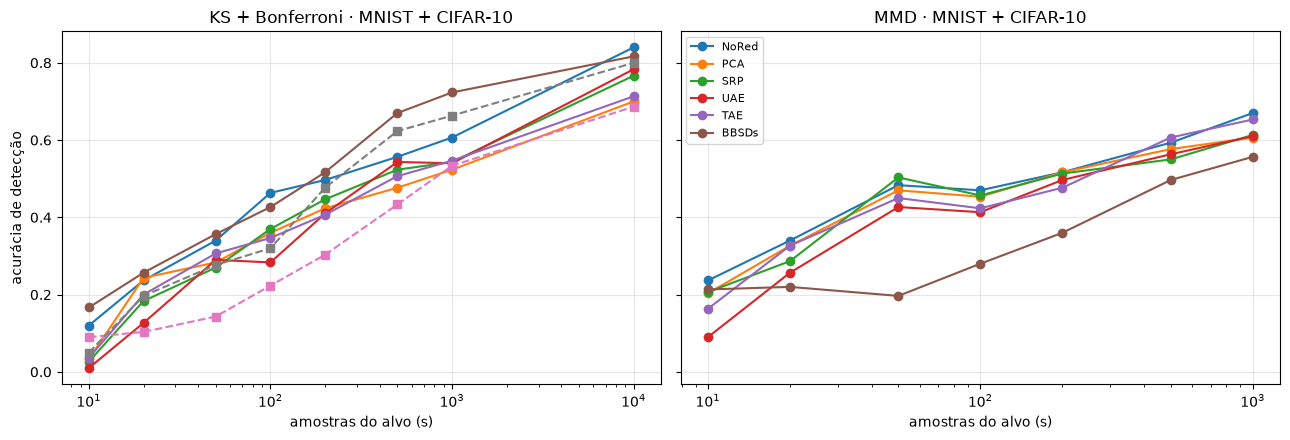

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, test in zip(axes, ["Univ", "Multiv"]):
    for d in DR_NAMES:
        ax.plot(ours.columns, ours.loc[(test, d)], marker="o", label=d)
    if test == "Univ":
        ax.plot(ours.columns, ours.loc[("χ²", "BBSDh")], marker="s", ls="--", label="BBSDh (χ²)")
        ax.plot(ours.columns, ours.loc[("Bin", "Classif")], marker="s", ls="--", label="Classif (bin)")
    ax.set_xscale("log"); ax.set_xlabel("amostras do alvo (s)")
    ax.set_title(("KS + Bonferroni" if test == "Univ" else "MMD") + " · MNIST + CIFAR-10")
    ax.grid(alpha=.3)
axes[0].set_ylabel("acurácia de detecção"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.3 Acurácia de detecção por tipo de shift (tabela 1b), com BBSDs univariado e UAE multivariado

In [12]:
by_shift = lambda test, dr: (shifted[(shifted.teste == test) & (shifted.dr == dr)]
                             .pivot_table(index="shift", columns="s", values="detect").reindex(KINDS).dropna(how="all"))
pd.concat({"Univ · BBSDs": by_shift("Univ", "BBSDs"), "Multiv · UAE": by_shift("Multiv", "UAE")}).round(2)

s                      10     20     50     100    200    500    1000   10000
             shift                                                           
Univ · BBSDs s_gn       0.00   0.00   0.00   0.00   0.00   0.10   0.10   0.00
             m_gn       0.00   0.00   0.00   0.03   0.07   0.27   0.33   0.67
             l_gn       0.40   0.53   0.67   0.70   0.77   0.87   1.00   1.00
             s_img      0.00   0.03   0.17   0.17   0.37   0.60   0.67   0.83
             m_img      0.13   0.23   0.33   0.57   0.67   0.87   0.87   1.00
             l_img      0.20   0.37   0.47   0.57   0.73   0.87   0.87   1.00
             adv        0.13   0.27   0.40   0.57   0.63   0.80   0.87   1.00
             ko         0.10   0.03   0.00   0.07   0.00   0.33   0.53   0.67
             m_img+ko   0.13   0.23   0.57   0.60   0.93   1.00   1.00   1.00
             oz+m_img   0.57   0.87   0.97   1.00   1.00   1.00   1.00   1.00
Multiv · UAE s_gn       0.00   0.10   0.20   0.10   0.10   0.00   0.00    NaN
             m_gn       0.00   0.10   0.20   0.07   0.07   0.07   0.17    NaN
             l_gn       0.13   0.40   0.53   0.63   0.67   0.70   0.70    NaN
             s_img      0.00   0.13   0.30   0.20   0.37   0.50   0.60    NaN
             m_img      0.07   0.37   0.60   0.57   0.70   0.80   0.80    NaN
             l_img      0.27   0.53   0.63   0.63   0.73   0.83   0.90    NaN
             adv        0.00   0.10   0.33   0.27   0.33   0.53   0.57    NaN
             ko         0.00   0.00   0.00   0.03   0.07   0.20   0.37    NaN
             m_img+ko   0.10   0.20   0.50   0.63   0.93   1.00   1.00    NaN
             oz+m_img   0.33   0.63   0.97   1.00   1.00   1.00   1.00    NaN

### 6.4 Efeito da fração afetada δ (BBSDs univariado)

In [13]:
(shifted[(shifted.teste == "Univ") & (shifted.dr == "BBSDs")]
 .pivot_table(index=["dataset", "delta"], columns="s", values="detect").round(2))

s              10     20     50     100    200    500    1000   10000
dataset delta                                                        
cifar10 0.1     0.06   0.10   0.10   0.14   0.22   0.46   0.42    0.6
        0.5     0.06   0.16   0.22   0.30   0.50   0.68   0.70    0.9
        1.0     0.20   0.30   0.42   0.52   0.66   0.86   0.84    0.9
mnist   0.1     0.14   0.16   0.20   0.28   0.32   0.48   0.66    0.7
        0.5     0.14   0.30   0.58   0.62   0.66   0.72   0.82    0.9
        1.0     0.40   0.52   0.62   0.70   0.74   0.82   0.90    0.9

## 7. Conclusões

- **Falsos positivos:** sem shift, 3,0% no MNIST e 4,7% no CIFAR-10, abaixo de α = 5%. Os testes estão calibrados.
- **BBSDs + KS continua sendo o melhor método univariado**, como no artigo: 0,72 de acurácia de detecção com 1.000 amostras (artigo: 0,70) e 0,82 com 10.000 (artigo: 0,79).
- **Diferença em relação ao artigo (MMD):** o autoencoder aleatório (UAE) não foi o melhor. Aplicar o MMD direto nos pixels (NoRed) foi igual ou melhor (0,67 contra 0,61 do UAE com 1.000 amostras).
- **O classificador de domínio** foi melhor que no artigo (0,66 contra 0,51 com 1.000 amostras).
- **O tipo de shift pesa mais que o método:** no CIFAR-10, com BBSDs e 1.000 amostras, o ruído gaussiano pequeno não é detectado (0%), enquanto o ruído grande e as combinações de shifts chegam a 100%. Quanto maior a fração afetada (δ), maior a detecção.
- **Limitações:**
  - no CIFAR-10 foi usada uma CNN simples (72% de acurácia) no lugar da ResNet-18 do artigo (cerca de 93%), o que tende a enfraquecer os métodos baseados no classificador;
  - foram 5 rodadas;
  - menos épocas de treino que no artigo.